# C0 · an additive-variance model for the one-sided transfer (free analysis 3 of 4)

**Idea.** Suppose the error variance along a target axis is the sum of an image term, which the target cannot change, and a
share k of the target's own variance along that axis:

SD_d² = s_d² + k · σ_d²,   so that   Δ log SD = ½ · log(1 + k · σ₀² · (e^{2x} − 1) / SD_B0,d²),   x = log(σ_d / σ₀).

SD_B0,d is the paired round baseline's spread along that axis (s_d² = SD_B0,d² − k σ₀²). If kσ₀² is small next to SD_B0², the model
predicts what arm A showed: narrowing can at most remove the small target term (a bounded gain), while widening adds k σ_d², which
grows without bound. It also predicts that widening hurts more along an axis whose baseline error is small (A⊥ long axes lie on the
baseline minor axis) than along the major axis (A∥ long axes), because the same k σ_d² is added to a smaller SD_B0². The log-linear
α model of §10 predicts the same slope for both.

**Status: exploratory, not pre-registered.** One parameter k per tier, plus the landmark intercepts used in §10, against the
log-linear α model with the same number of parameters. The model is then checked out of sample on the round-width arm R runs,
which were not used to fit k.

In [1]:
ANALYSIS = "additive_variance"
import os, json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
W_ROOT = Path(os.environ.get("C0_WEIGHTS", "/tf/weights/C0" if os.path.isdir("/tf/weights/C0") else str(_REPO / "weights" / "C0")))
OUT = W_ROOT / "analyses" / ANALYSIS
OUT.mkdir(parents=True, exist_ok=True)
PD = "quadratic"
MM_PER_PX = 0.3125
TIERS = {"High": {"net": "UNet-64", "sigma0_px": 5.0, "b0": "1.00", "protocol": "093467c2293e4792", "arm": "47b9c6388cce8c42"},
         "Medium": {"net": "UNet-32", "sigma0_px": 5.0 * 2 ** 0.5, "b0": "1.41", "protocol": "09b9ae2a23fe2266", "arm": "6505f2d9c645689e"}}
COLORS = {"High": "#0072B2", "Medium": "#D55E00"}
MIN_OBS = 8
N_BOOT = 500

def load_obs(t):
    agg = W_ROOT / f"ISBI2015_{t}" / "arm_A_summary"
    pool = json.loads((agg / "alpha_pooled.json").read_text())
    assert pool["protocol_hash"] == TIERS[t]["protocol"] and pool["arm_hash"] == TIERS[t]["arm"], f"{t}: unexpected arm A analysis"
    o = pd.read_csv(agg / "arm_A_axis_observations.csv")
    o = o[(o.decoder == PD)].copy()
    o = o[o.usable.astype(bool)]
    keep = o.groupby("landmark").size()
    return o[o.landmark.isin(keep[keep >= MIN_OBS].index)].reset_index(drop=True)

OBS = {t: load_obs(t) for t in TIERS}
NAMES = pd.read_csv(W_ROOT / "ISBI2015_High" / "arm_A_summary" / "alpha_by_landmark.csv").set_index("landmark").name
print({t: (len(o), o.landmark.nunique()) for t, o in OBS.items()})

{'High': (714, 15), 'Medium': (718, 15)}


## 1. Fits

Four models per tier, each with and without landmark intercepts c_i (the intercept absorbs a run-level shift of all oval runs at
a landmark; §10 uses it). Common-parameter models: **α** (Δ = c_i + α x) and **additive** (Δ = c_i + ½ log(1 + kσ₀²(e^{2x}−1)/SD_B0²)).
Per-landmark versions (α_i, k_i) are reported for completeness. k is bounded so that every narrowed-axis prediction stays defined.
The 95 % interval for k is a landmark-cluster bootstrap.

In [2]:
def g_add(x, k, s0, v0):
    return 0.5 * np.log(np.clip(1 + k * s0 ** 2 * (np.exp(2 * x) - 1) / v0, 1e-9, None))

def k_bounds(o, s0):
    v0 = o.sd_b0.values ** 2
    return 0.0, 0.999 * v0.min() / (0.75 * s0 ** 2)

def fit_add(o, s0, intercept=True):
    x, y, v0, lm = o.x.values, o.dlog_sd.values, o.sd_b0.values ** 2, o.landmark.values
    def sse(k):
        r = y - g_add(x, k, s0, v0)
        if intercept:
            r = r - pd.Series(r).groupby(lm).transform("mean").values
        return float(r @ r)
    lo, hi = k_bounds(o, s0)
    res = optimize.minimize_scalar(sse, bounds=(lo, hi), method="bounded", options={"xatol": 1e-7})
    return res.x, res.fun, hi

def fit_alpha(o, intercept=True):
    x, y, lm = o.x.values, o.dlog_sd.values, o.landmark.values
    if intercept:
        x = x - pd.Series(x).groupby(lm).transform("mean").values
        y = y - pd.Series(y).groupby(lm).transform("mean").values
    a = float((x * y).sum() / (x * x).sum())
    r = y - a * x
    return a, float(r @ r)

def aic(sse, n, p):
    return n * math.log(sse / n) + 2 * p

FIT, rows = {}, []
for t, o in OBS.items():
    s0 = TIERS[t]["sigma0_px"] * MM_PER_PX
    n, L = len(o), o.landmark.nunique()
    for ic in (True, False):
        k, sse_k, kmax = fit_add(o, s0, ic)
        a, sse_a = fit_alpha(o, ic)
        p_extra = L if ic else 0
        rows += [{"tier": t, "intercepts": ic, "model": "additive (common k)", "param": k, "sse": sse_k, "aic": aic(sse_k, n, 1 + p_extra), "k_upper_bound": kmax},
                 {"tier": t, "intercepts": ic, "model": "log-linear (common α)", "param": a, "sse": sse_a, "aic": aic(sse_a, n, 1 + p_extra)}]
        FIT[(t, ic)] = {"k": k, "alpha": a}
    # per-landmark versions (with intercepts)
    sse_ki = sse_ai = 0.0
    for lm, g in o.groupby("landmark"):
        sse_ki += fit_add(g, s0, True)[1]
        sse_ai += fit_alpha(g, True)[1]
    rows += [{"tier": t, "intercepts": True, "model": "additive (k_i per landmark)", "param": np.nan, "sse": sse_ki, "aic": aic(sse_ki, n, 2 * L)},
             {"tier": t, "intercepts": True, "model": "log-linear (α_i per landmark, §10)", "param": np.nan, "sse": sse_ai, "aic": aic(sse_ai, n, 2 * L)}]
MODELS = pd.DataFrame(rows)

# bootstrap for k (common, with intercepts), resampling landmarks
rng = np.random.default_rng(7)
K_CI = {}
for t, o in OBS.items():
    s0 = TIERS[t]["sigma0_px"] * MM_PER_PX
    lms = o.landmark.unique()
    groups = {lm: g for lm, g in o.groupby("landmark")}
    ks = []
    for _ in range(N_BOOT):
        pick = rng.choice(lms, len(lms), replace=True)
        ob = pd.concat([groups[lm].assign(landmark=j) for j, lm in enumerate(pick)], ignore_index=True)
        ks.append(fit_add(ob, s0, True)[0])
    K_CI[t] = {"k": FIT[(t, True)]["k"], "ci95": [float(np.percentile(ks, 2.5)), float(np.percentile(ks, 97.5))],
               "k_upper_bound": float(k_bounds(o, s0)[1]), "sigma0_mm": s0}
MODELS.to_csv(OUT / "additive_model_comparison.csv", index=False)
(OUT / "additive_model_k.json").write_text(json.dumps(K_CI, indent=1))
display(pd.DataFrame(K_CI).T)
MODELS.round(4)

,k,ci95,k_upper_bound,sigma0_mm
High,0.004962,"[0.0037300936423935805, 0.007198875317686144]",0.027648,1.5625
Medium,0.004336,"[0.0032727568379983902, 0.0055543421058519265]",0.015928,2.209709


,tier,intercepts,model,param,sse,aic,k_upper_bound
0,High,True,additive (common k),0.0050,3.6231,-3740.4532,0.0276
1,High,True,log-linear (common α),0.0644,4.1432,-3644.6875,NaN
2,High,False,additive (common k),0.0053,3.8313,-3730.5539,0.0276
3,High,False,log-linear (common α),0.0644,4.6048,-3599.2575,NaN
4,High,True,additive (k_i per landmark),NaN,3.1277,-3817.4353,NaN
5,High,True,"log-linear (α_i per landmark, §10)",NaN,3.9513,-3650.5353,NaN
6,Medium,True,additive (common k),0.0043,3.0468,-3889.9897,0.0159
7,Medium,True,log-linear (common α),0.0850,4.3380,-3636.3101,NaN
8,Medium,False,additive (common k),0.0047,3.6198,-3796.2644,0.0159
9,Medium,False,log-linear (common α),0.0850,5.6469,-3476.9670,NaN


## 2. Which pattern does each model predict?

Observed and predicted mean Δ log SD per arm, axis and ratio (common-parameter models with intercepts). The additive model's
prediction differs between A∥ and A⊥ only through the baseline spread along the axis concerned.

In [3]:
cells = []
for t, o in OBS.items():
    s0 = TIERS[t]["sigma0_px"] * MM_PER_PX
    k, a = FIT[(t, True)]["k"], FIT[(t, True)]["alpha"]
    q = o.copy()
    q["pred_add_raw"] = g_add(q.x.values, k, s0, q.sd_b0.values ** 2)
    q["pred_add"] = q.pred_add_raw + (q.dlog_sd - q.pred_add_raw).groupby(q.landmark).transform("mean")
    q["pred_alpha"] = a * q.x + (q.dlog_sd - a * q.x).groupby(q.landmark).transform("mean")
    c = q.groupby(["arm", "axis", "ratio"]).agg(x=("x", "mean"), observed=("dlog_sd", "mean"), additive=("pred_add", "mean"),
                                               log_linear=("pred_alpha", "mean"), n=("dlog_sd", "size")).reset_index()
    cells.append(c.assign(tier=t))
CELLS = pd.concat(cells, ignore_index=True)
CELLS.round(4).to_csv(OUT / "additive_model_cell_means.csv", index=False)
fitq = CELLS.assign(e_add=(CELLS.observed - CELLS.additive) ** 2, e_lin=(CELLS.observed - CELLS.log_linear) ** 2)
display(fitq.groupby("tier")[["e_add", "e_lin"]].mean().pow(0.5).rename(columns={"e_add": "RMSE cell means, additive",
                                                                                  "e_lin": "RMSE cell means, log-linear"}).round(4))
CELLS.pivot_table(index=["arm", "axis", "ratio"], columns="tier", values=["observed", "additive", "log_linear"]).round(3)

,"RMSE cell means, additive","RMSE cell means, log-linear"
tier,,
High,0.0229,0.0379
Medium,0.0140,0.0374


additive        log_linear        observed       
tier                  High Medium       High Medium     High Medium
arm   axis  ratio                                                  
Apar  long  1.5      0.012  0.028      0.031  0.052   -0.022  0.018
            2.0      0.017  0.036      0.040  0.065    0.003  0.021
            3.0      0.027  0.051      0.053  0.082   -0.005  0.032
            4.0      0.036  0.066      0.062  0.094    0.045  0.071
      short 1.5     -0.005  0.001      0.005  0.018   -0.015  0.000
            2.0     -0.012 -0.009     -0.005  0.006   -0.003 -0.017
            3.0     -0.019 -0.019     -0.017 -0.012   -0.028 -0.023
            4.0     -0.022 -0.024     -0.027 -0.024   -0.003 -0.013
Aperp long  1.5      0.025  0.046      0.031  0.052    0.017  0.040
            2.0      0.042  0.071      0.040  0.065    0.044  0.067
            3.0      0.074  0.117      0.053  0.082    0.125  0.127
            4.0      0.106  0.155      0.063  0.094    0.149  0.197
      short 1.5      0.004  0.014      0.005  0.018   -0.005  0.011
            2.0      0.002  0.012     -0.005  0.006   -0.014  0.003
            3.0      0.000  0.009     -0.018 -0.011    0.015  0.007
            4.0     -0.001  0.007     -0.026 -0.024   -0.016  0.022

## 3. How much of the baseline spread is the target's? The ceiling on narrowing gains

φ = k σ₀² / SD_B0² is the share of the round baseline's error variance along an axis that the model attributes to the target.
Narrowing that axis to half the round width (ratio-4 short axis) can at best change log SD by ½ log(1 − 0.75 φ); shrinking the target
to zero width, by ½ log(1 − φ). This is the most any target-shape rule could gain along that axis under the model.

In [4]:
rows = []
for t, o in OBS.items():
    s0 = TIERS[t]["sigma0_px"] * MM_PER_PX
    k = FIT[(t, True)]["k"]
    v = o.drop_duplicates(["seed", "landmark", "direction"]).groupby(["landmark", "direction"]).sd_b0.apply(lambda s: np.mean(s ** 2))
    for (lm, dr), v0 in v.items():
        phi = k * s0 ** 2 / v0
        rows.append({"tier": t, "landmark": lm, "name": NAMES[lm], "direction": dr, "sd_b0_mm": math.sqrt(v0), "target_share_phi": phi,
                     "best_dlogsd_half_width": 0.5 * math.log(1 - 0.75 * phi), "best_dlogsd_zero_width": 0.5 * math.log(1 - phi)})
SHARE = pd.DataFrame(rows)
SHARE.round(4).to_csv(OUT / "additive_model_target_share.csv", index=False)
SHARE.groupby(["tier", "direction"])[["sd_b0_mm", "target_share_phi", "best_dlogsd_half_width", "best_dlogsd_zero_width"]].median().round(4)

sd_b0_mm  ...  best_dlogsd_zero_width
tier   direction            ...                        
High   u            0.9037  ...                 -0.0075
       v            0.4737  ...                 -0.0277
Medium u            0.8966  ...                 -0.0133
       v            0.5296  ...                 -0.0392

[4 rows x 4 columns]

## 4. Out-of-sample check on the round-width runs (arm R)

Each arm R run at width w (paired seeds 1–3) against the tier's B0 run of the same seed, isotropic spread `sd_iso`, usable cells only
(≤ 5 % gross failures in both). Prediction with the arm A k: Δ log SD_iso = ½ log(1 + kσ₀²(w_rel² − 1)/SD_iso,B0²), w_rel = w / w_B0.
The log-linear prediction is α · log w_rel with the arm A α (no intercept, so both models predict 0 at w_rel = 1).

In [5]:
rows = []
for t in TIERS:
    s0 = TIERS[t]["sigma0_px"] * MM_PER_PX
    rt = pd.read_csv(W_ROOT / f"ISBI2015_{t}" / "arm_R_summary" / "arm_R_landmark_table_all_decoders.csv")
    rt = rt[(rt.decoder == PD) & rt.seed.isin([1, 2, 3])]
    b0 = rt[np.isclose(rt.width_mult, float(TIERS[t]["b0"]), atol=0.01)].set_index(["seed", "landmark"])
    k, a = FIT[(t, True)]["k"], FIT[(t, False)]["alpha"]
    for _, r in rt.iterrows():
        if (r.seed, r.landmark) not in b0.index or np.isclose(r.width_mult, float(TIERS[t]["b0"]), atol=0.01):
            continue
        b = b0.loc[(r.seed, r.landmark)]
        if r.fail_rate > 0.05 or b.fail_rate > 0.05 or not (r.sd_iso > 0 and b.sd_iso > 0):
            continue
        w_rel = r.width_mult / b.width_mult
        rows.append({"tier": t, "landmark": r.landmark, "seed": r.seed, "w_rel": round(w_rel, 3),
                     "observed": math.log(r.sd_iso / b.sd_iso),
                     "additive": float(g_add(np.array([math.log(w_rel)]), k, s0, np.array([b.sd_iso ** 2]))[0]),
                     "log_linear": a * math.log(w_rel)})
OOS = pd.DataFrame(rows)
OOS.round(4).to_csv(OUT / "additive_model_arm_R_check.csv", index=False)
oos_w = OOS.groupby(["tier", "w_rel"])[["observed", "additive", "log_linear"]].mean().join(OOS.groupby(["tier", "w_rel"]).size().rename("n"))
oos_rmse = OOS.assign(e_add=(OOS.observed - OOS.additive) ** 2, e_lin=(OOS.observed - OOS.log_linear) ** 2, e_0=OOS.observed ** 2) \
    .groupby("tier")[["e_add", "e_lin", "e_0"]].mean().pow(0.5)
oos_rmse.columns = ["RMSE additive", "RMSE log-linear", "RMSE 'no change'"]
display(oos_rmse.round(4))
oos_w.round(4)

,RMSE additive,RMSE log-linear,RMSE 'no change'
tier,,,
High,0.0511,0.0576,0.0613
Medium,0.0521,0.0606,0.0617


observed  additive  log_linear   n
tier   w_rel                                    
High   0.500   -0.0144   -0.0122     -0.0447  27
       0.707    0.0046   -0.0069     -0.0223  44
       1.414    0.0328    0.0138      0.0223  45
       2.000    0.0413    0.0400      0.0447  45
Medium 0.354   -0.0133   -0.0244     -0.0884  15
       0.500   -0.0330   -0.0185     -0.0589  29
       0.707   -0.0164   -0.0109     -0.0295  42
       1.414    0.0468    0.0219      0.0295  45

## 5. Figure

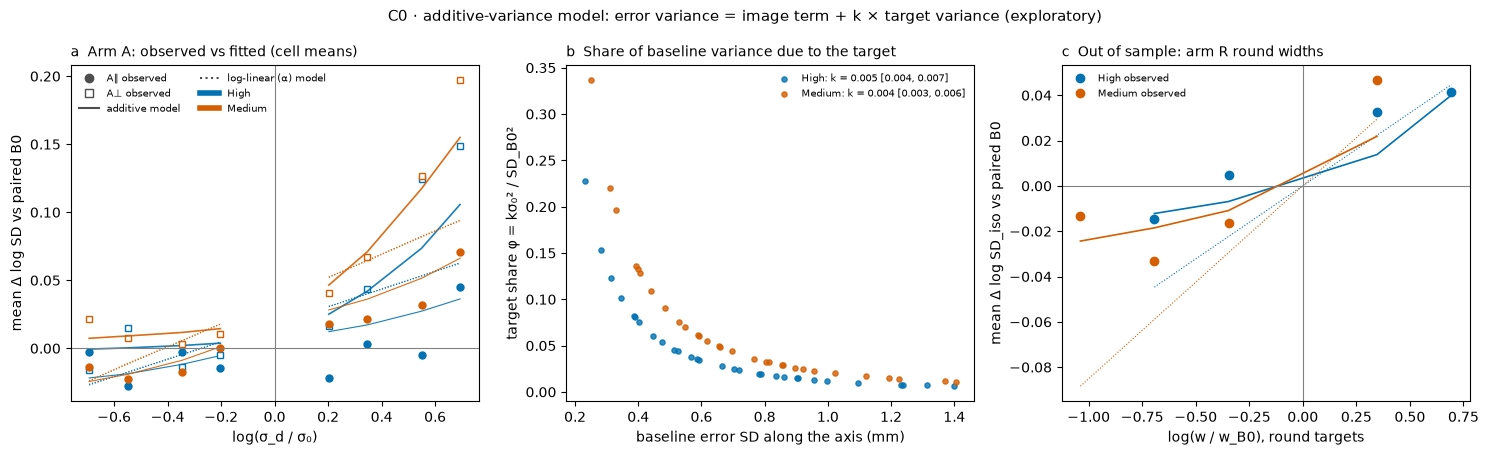

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axs[0]
mk = {("Apar", "long"): "o", ("Apar", "short"): "o", ("Aperp", "long"): "s", ("Aperp", "short"): "s"}
for t in TIERS:
    c = CELLS[CELLS.tier == t]
    for (arm, axis), g in c.groupby(["arm", "axis"]):
        g = g.sort_values("x")
        ax.plot(g.x, g.observed, mk[(arm, axis)], color=COLORS[t], mfc=COLORS[t] if arm == "Apar" else "white", ms=5)
        ax.plot(g.x, g.additive, "-", color=COLORS[t], lw=1.2 if arm == "Aperp" else 0.8, alpha=0.9)
        ax.plot(g.x, g.log_linear, ":", color=COLORS[t], lw=0.8)
ax.plot([], [], "o", color="0.3", label="A∥ observed"); ax.plot([], [], "s", color="0.3", mfc="white", label="A⊥ observed")
ax.plot([], [], "-", color="0.3", label="additive model"); ax.plot([], [], ":", color="0.3", label="log-linear (α) model")
for t in TIERS:
    ax.plot([], [], "-", color=COLORS[t], lw=4, label=t)
ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("log(σ_d / σ₀)"); ax.set_ylabel("mean Δ log SD vs paired B0")
ax.set_title("a  Arm A: observed vs fitted (cell means)", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False, ncol=2)

ax = axs[1]
for t in TIERS:
    g = SHARE[SHARE.tier == t]
    ax.scatter(g.sd_b0_mm, g.target_share_phi, s=14, color=COLORS[t], alpha=0.8, label=f"{t}: k = {K_CI[t]['k']:.3f} "
               f"[{K_CI[t]['ci95'][0]:.3f}, {K_CI[t]['ci95'][1]:.3f}]")
ax.set_xlabel("baseline error SD along the axis (mm)"); ax.set_ylabel("target share φ = kσ₀² / SD_B0²")
ax.set_title("b  Share of baseline variance due to the target", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)

ax = axs[2]
for t in TIERS:
    m = oos_w.loc[t]
    ax.plot(np.log(m.index), m.observed, "o", color=COLORS[t], ms=6, label=f"{t} observed")
    ax.plot(np.log(m.index), m.additive, "-", color=COLORS[t], lw=1.2)
    ax.plot(np.log(m.index), m.log_linear, ":", color=COLORS[t], lw=0.8)
ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("log(w / w_B0), round targets"); ax.set_ylabel("mean Δ log SD_iso vs paired B0")
ax.set_title("c  Out of sample: arm R round widths", loc="left", fontsize=10); ax.legend(fontsize=7, frameon=False)
fig.suptitle("C0 · additive-variance model: error variance = image term + k × target variance (exploratory)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "additive_variance.png", dpi=150)